### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [4]:
# Custom Function
from custom_function import *

In [5]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

### Loading

#### 1. Food Price

In [6]:
food_price = get_dataset('\\Datasets\\wfp_food_prices_mmr(Cleaned).csv')
food_price.drop(['latitude', 'longitude'],  axis='columns', inplace=True)
food_price.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [7]:
food_price = food_price[['date', 'price']]
food_price['date'] = pd.to_datetime(food_price['date'])
food_price.columns = ['date', 'food_price']
food_price = food_price.set_index('date')
food_price = food_price.resample('AS-JAN').mean()
food_price.head()

,food_price
date,
2008-01-01,1002.766567
2009-01-01,805.337847
2010-01-01,900.166229
2011-01-01,972.709289
2012-01-01,832.871728


#### 2. Wage Workers Dataset

In [8]:
temp_wage_workers = get_dataset('\\Datasets\\wage_workers.csv')
temp_wage_workers.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
0,Aruba,ABW,"Wage and salaried workers, total (% of total e...",SL.EMP.WORK.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,"Wage and salaried workers, total (% of total e...",SL.EMP.WORK.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,25.019524,25.542508,26.036749,26.508860,26.846345,27.060362,27.324366,27.646561,27.716942,NaN
2,Afghanistan,AFG,"Wage and salaried workers, total (% of total e...",SL.EMP.WORK.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,12.110000,13.370000,14.340000,15.130000,15.790000,16.500000,17.549999,17.660000,17.809999,NaN
3,Africa Western and Central,AFW,"Wage and salaried workers, total (% of total e...",SL.EMP.WORK.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,17.756552,18.069598,17.982672,18.273976,18.056644,18.109983,18.912272,19.533026,20.059988,NaN
4,Angola,AGO,"Wage and salaried workers, total (% of total e...",SL.EMP.WORK.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,28.100000,27.889999,26.990000,25.520000,24.230000,23.430000,22.600000,21.620001,21.490000,NaN


In [9]:
temp_wage_workers = temp_wage_workers[temp_wage_workers['Country Code'] == 'MMR']
temp_wage_workers

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
160,Myanmar,MMR,"Wage and salaried workers, total (% of total e...",SL.EMP.WORK.ZS,NaN,NaN,NaN,NaN,NaN,NaN,...,31.969999,32.759998,33.66,34.48,35.310001,36.02,36.759998,34.41,35.080002,NaN


In [10]:
date = temp_wage_workers.columns
date = date[4:]
date

Index(['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
       '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
       '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
       '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
       '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020'],
      dtype='object')

In [11]:
date.shape

(61,)

In [12]:
wage_workers_percent = temp_wage_workers.copy()
wage_workers_percent = wage_workers_percent[date]
wage_workers_percent = wage_workers_percent.values
wage_workers_percent

array([[        nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan, 16.82999992, 16.98999977, 17.12000084, 17.35000038,
        17.60000038, 17.88999939, 18.18000031, 18.47999954, 19.09000015,
        19.93000031, 20.85000038, 21.82999992, 22.95000076, 24.11000061,
        25.34000015, 26.61000061, 27.88999939, 29.04999924, 30.23999977,
        31.32999992, 31.96999931, 32.75999832, 33.65999985, 34.47999954,
        35.31000137, 36.02000046, 36.75999832, 34.40999985, 35.08000183,
                nan]])

In [13]:
date = pd.to_datetime(date, format='%Y')

In [14]:
wage_workers_percent = wage_workers_percent[0]
wage_workers_percent.shape

(61,)

In [15]:
wage_workers = pd.DataFrame()
wage_workers['wage_workers_percent'] = wage_workers_percent
wage_workers

,wage_workers_percent
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN
...,...
56,36.020000
57,36.759998
58,34.410000
59,35.080002


In [16]:
wage_workers['date']=date
wage_workers = wage_workers.set_index('date')
wage_workers.columns=['wage_workers_percent']
wage_workers.head()

,wage_workers_percent
date,
1960-01-01,NaN
1961-01-01,NaN
1962-01-01,NaN
1963-01-01,NaN
1964-01-01,NaN


In [17]:
wage_workers.dropna(inplace=True)
wage_workers.head()

,wage_workers_percent
date,
1991-01-01,16.830000
1992-01-01,16.990000
1993-01-01,17.120001
1994-01-01,17.350000
1995-01-01,17.600000


### Merge wage_workers_percent and food_price

In [18]:
food_wage = food_price.join(wage_workers, how='inner')
food_wage

,food_price,wage_workers_percent
date,,
2008-01-01,1002.766567,29.049999
2009-01-01,805.337847,30.240000
2010-01-01,900.166229,31.330000
2011-01-01,972.709289,31.969999
2012-01-01,832.871728,32.759998
2013-01-01,914.454042,33.660000
2014-01-01,1634.163191,34.480000
2015-01-01,1885.676491,35.310001
2016-01-01,2105.188314,36.020000


### Correlation

In [19]:
correlation=food_wage['food_price'].corr(food_wage['wage_workers_percent'])
correlation

0.8236184173431591

### Make scatter plot

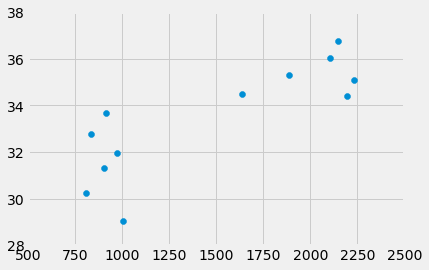

In [20]:
plt.scatter(food_wage['food_price'],food_wage['wage_workers_percent'])
plt.show()

### Normalization

In [21]:
date = food_wage.index

In [22]:
scaler = MinMaxScaler()

In [23]:
food_wage = scaler.fit_transform(food_wage)
food_wage = pd.DataFrame(food_wage)
food_wage['date'] = date
food_wage.set_index('date', inplace=True)
food_wage.columns = ['food_price', 'wage_workers_percent']
food_wage.head()

,food_price,wage_workers_percent
date,,
2008-01-01,0.138512,0.000000
2009-01-01,0.000000,0.154345
2010-01-01,0.066530,0.295720
2011-01-01,0.117424,0.378729
2012-01-01,0.019317,0.481193


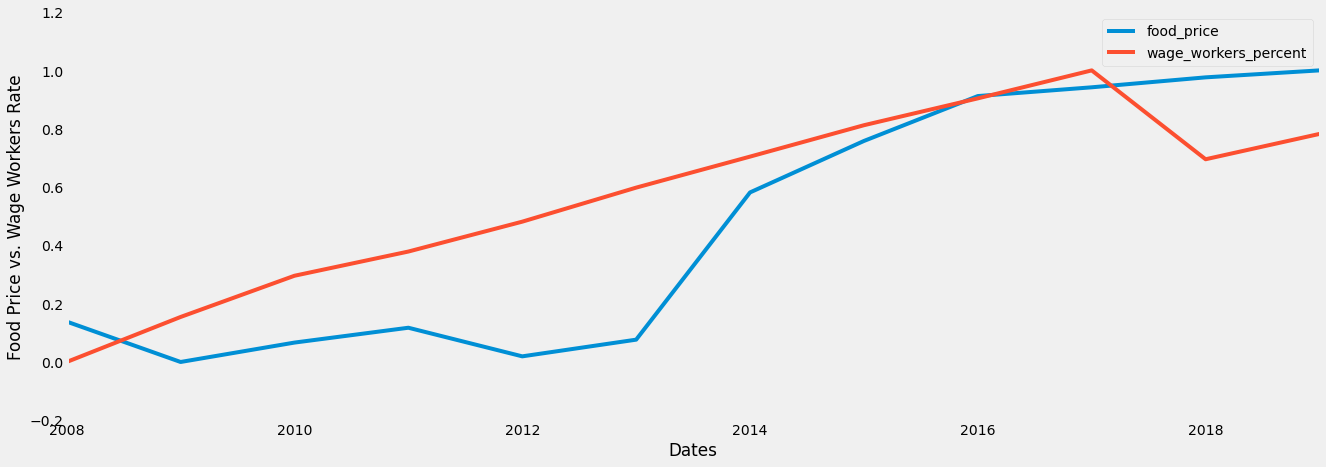

In [24]:
line_ax = food_wage.plot(kind='line', figsize=(20, 7))
line_ax.set_ylabel('Food Price vs. Wage Workers Rate')
line_ax.set_xlabel('Dates')
line_ax.grid()

<span style="color:red">There is positive relation between Food Price and Wage Workers Percent</span>